<a href="https://colab.research.google.com/github/semualachew-alex/APHI-/blob/main/The_last_maternal_satisfaction_pridiction_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Note:** This is an annotated version of the original notebook. A short **Explanation** cell (in *italic bold*, starting with "**Explanation:**") has been added directly after each code cell to describe, in plain language, what that code does. The final default "Welcome to Colab" cells (which are not part of this project) have been removed for clarity.


# ***Machine learning  project in  APHI***


#  *** delivery care satisfaction***

 1,  importing the dependencies (necessary libraries)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.metrics import accuracy_score,confusion_matrix,f1_score,recall_score,precision_score,brier_score_loss,roc_curve
from sklearn.feature_selection import SelectKBest,f_classif
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

**Explanation:** This cell imports every library the project needs.
- `pandas` / `numpy` — load and manipulate the tabular data.
- `matplotlib.pyplot` / `seaborn` — draw charts (histograms, box plots, heatmaps, ROC curve).
- `train_test_split`, `cross_val_score` — split data into training/testing sets.
- `LogisticRegression` — the classification model used to predict satisfaction.
- `StandardScaler`, `OneHotEncoder`, `ColumnTransformer`, `Pipeline` — tools for scaling numeric data and encoding categorical data.
- `accuracy_score`, `confusion_matrix`, `f1_score`, `recall_score`, `precision_score`, `brier_score_loss`, `roc_curve`, `roc_auc_score` — metrics used later to judge how good the model is.
- `SelectKBest`, `f_classif` — statistical feature-selection tools that pick the most useful variables.
- `permutation_importance` — measures how much each feature matters to the trained model.


loading the data set


2,  Loading a dataset

In [3]:
!pip install pyreadstat

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 17.9 MB/s  0:00:00


**Explanation:** Installs the `pyreadstat` package. This package is required so that pandas can read `.sav` files, which is the native file format used by SPSS (a statistics program). Without it, `pd.read_spss()` in the next cell would fail.


In [4]:
df=pd.read_spss('/content/Delivery care satisfaction.sav')
df

,q101age,q102mstatu,q103religi,q104ethini,q105educat,q106occupa,q107mincom,q108reside,q1091distk,q1092disth,...,encourageandsupportatdeliveryrecode,politenessrecode,availabilityofmedicalequipmentsrecode,counselingrecode,overallcleanessrecode,accessandcleanessoftoiletrecode,waitingareacleanessandconfort,availabilityofbedintheward,distancerecode1,wolkingdistancerecodeinhrs
0,22.0,married,orthodox,amhara,grade 5 to 8,others,800.0,rural,0.0,200.0,...,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,<=10 kilo meters,>2 hrs
1,35.0,married,orthodox,tigrie,grade 5 to 8,merchants,7000.0,urban,0.0,50.0,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,>2 hrs
2,20.0,married,orthodox,amhara,grade 9 to 10,merchants,1500.0,urban,5.0,NaN,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,NaN
3,26.0,married,orthodox,amhara,grade 1 to 4,huose wife,900.0,urban,0.0,11.0,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,>2 hrs
4,22.0,married,muslim,amhara,grade 11 to 12,students,1536.0,rural,5.0,NaN,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
889,29.0,cohabited,muslim,oromo,grade 11 to 12,others,2200.0,urban,30.0,NaN,...,not satisfied,not satisfied,satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,>10 kilo meters,NaN
890,31.0,married,orthodox,amhara,diploma and above,governmental,4530.0,urban,20.0,NaN,...,not satisfied,not satisfied,satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,>10 kilo meters,NaN
891,21.0,married,orthodox,amhara,grade 11 to 12,huose wife,2500.0,urban,0.0,1.0,...,not satisfied,not satisfied,satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,<=10 kilo meters,NaN
892,18.0,single,muslim,amhara,diploma and above,governmental,3230.0,urban,15.0,NaN,...,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,>10 kilo meters,NaN


**Explanation:** Loads the dataset `Delivery care satisfaction (2).sav` (an SPSS file) into a pandas DataFrame called `df`, then displays the DataFrame so we can see the raw data (rows = survey respondents, columns = survey questions/variables).


Observing few structures of the data

In [5]:
df.head()

,q101age,q102mstatu,q103religi,q104ethini,q105educat,q106occupa,q107mincom,q108reside,q1091distk,q1092disth,...,encourageandsupportatdeliveryrecode,politenessrecode,availabilityofmedicalequipmentsrecode,counselingrecode,overallcleanessrecode,accessandcleanessoftoiletrecode,waitingareacleanessandconfort,availabilityofbedintheward,distancerecode1,wolkingdistancerecodeinhrs
0,22.0,married,orthodox,amhara,grade 5 to 8,others,800.0,rural,0.0,200.0,...,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,not satisfied,<=10 kilo meters,>2 hrs
1,35.0,married,orthodox,tigrie,grade 5 to 8,merchants,7000.0,urban,0.0,50.0,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,>2 hrs
2,20.0,married,orthodox,amhara,grade 9 to 10,merchants,1500.0,urban,5.0,NaN,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,NaN
3,26.0,married,orthodox,amhara,grade 1 to 4,huose wife,900.0,urban,0.0,11.0,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,>2 hrs
4,22.0,married,muslim,amhara,grade 11 to 12,students,1536.0,rural,5.0,NaN,...,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,satisfied,<=10 kilo meters,NaN


**Explanation:** `df.head()` shows the first 5 rows of the dataset. This is a quick sanity check to see what the columns and values actually look like before doing any real analysis.


Doing summary statistics (Descreptive statistics)

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
q101age,894.0,26.602908,4.881351,17.0,23.00,27.0,30.0,42.0
q107mincom,894.0,4096.879195,4470.313904,200.0,1537.75,3000.0,5300.0,50000.0
q1091distk,894.0,19.286353,44.228470,0.0,0.00,5.0,15.0,500.0
q1092disth,320.0,16.671875,16.815293,1.0,4.00,12.0,30.0,200.0
q205ga,894.0,39.395973,1.550864,32.0,39.00,39.0,40.0,43.0
q2010bw,894.0,2941.728188,540.414864,1111.0,2600.00,2900.0,3200.0,5001.0


**Explanation:** `df.describe().T` computes summary/descriptive statistics (count, mean, standard deviation, min, quartiles, max) for every numeric column, then `.T` transposes the table so each row is a variable instead of a statistic — easier to read when there are many columns.


Doing variance of the numerical variables

In [7]:
df.var(numeric_only=True)

,0
q101age,2.382758e+01
q107mincom,1.998371e+07
q1091distk,1.956158e+03
q1092disth,2.827541e+02
q205ga,2.405180e+00
q2010bw,2.920482e+05


**Explanation:** `df.var(numeric_only=True)` calculates the statistical variance of each numeric column, showing how spread out the values of each numeric variable are.


to know the number of columns in the dataset

In [8]:
df.columns.size

46

**Explanation:** `df.columns.size` simply counts and prints how many columns (variables) exist in the raw dataset.


Checking the total null values of the dataset

In [9]:
df.isnull().sum().sum()


np.int64(1193)

**Explanation:** `df.isnull().sum().sum()` counts missing (null) values in every column and then sums those counts together, giving the single total number of missing values in the whole dataset.


Identifing the columns that contains the null values  and tells howmany rows are null

In [10]:
df.isna().sum()

,0
q101age,0
q102mstatu,0
q103religi,0
q104ethini,0
q105educat,0
q106occupa,0
q107mincom,0
q108reside,0
q1091distk,0
q1092disth,574


**Explanation:** `df.isna().sum()` counts the number of missing values *per column*, so we can see exactly which variables have missing data and how much.


Checking duplicates

In [11]:
df.duplicated().any()

np.False_

**Explanation:** `df.duplicated().any()` checks whether the dataset contains any fully duplicated rows (i.e., the same respondent's answers repeated), returning `True` or `False`.


Droping columns that have a null values more than 50%

In [12]:
df_clean=df.drop(columns=['wolkingdistancerecodeinhrs','q1092disth'])

**Explanation:** Creates a cleaned copy of the data, `df_clean`, by dropping the two columns (`wolkingdistancerecodeinhrs` and `q1092disth`) that were found to have more than 50% missing values — too many gaps to reliably use them in modeling.


In [13]:
df_clean.shape

(894, 44)

**Explanation:** `df_clean.shape` prints the (rows, columns) dimensions of the cleaned dataset, confirming the two columns were removed.


splitting the target(dependent and its independent variables)

In [15]:
x=df_clean.drop(columns=['satisfaction'],axis=1)
y=df_clean['satisfaction']

**Explanation:** Splits the cleaned data into inputs and output for machine learning:
- `x` = all columns except `satisfaction` (the independent/predictor variables).
- `y` = the `satisfaction` column alone (the dependent/target variable the model will try to predict).


In [17]:
df_clean['satisfaction'].value_counts()

,count
satisfaction,
satisfied,549
not satisfied,345


**Explanation:** `df_clean['satisfaction'].value_counts()` shows how many respondents fall into each class of the target variable (e.g. how many are "satisfied" vs "not satisfied"), which reveals whether the classes are balanced or imbalanced.


In [16]:
x.shape

(894, 43)

**Explanation:** `x.shape` prints the number of rows and predictor columns in the feature set, confirming the target column was successfully removed.


identifing the categotical and numerical variables

In [18]:

numerical_features=x.select_dtypes(include=np.number).columns
categorical_features=x.select_dtypes(exclude=np.number).columns

**Explanation:** Splits the predictor columns `x` into two groups based on data type:
- `numerical_features` — columns with numeric dtypes.
- `categorical_features` — columns with non-numeric (text/category) dtypes.
This separation is needed because numeric and categorical variables must be preprocessed differently later (scaling vs. encoding).


*doing the frequency for each categorical variable*

In [19]:
for a in categorical_features:
  print(x[a].value_counts())

q102mstatu
married      712
single        98
cohabited     67
widowed       10
divorced       7
Name: count, dtype: int64
q103religi
orthodox      608
muslim        193
protestant     88
88.0            5
Name: count, dtype: int64
q104ethini
amhara    715
oromo      95
agew       47
tigrie     37
Name: count, dtype: int64
q105educat
diploma and above           321
grade 11 to 12              154
grade 9 to 10               146
unable to read and write    117
grade 5 to 8                 80
able to read and write       49
grade 1 to 4                 27
Name: count, dtype: int64
q106occupa
huose wife      288
governmental    263
merchants       128
others          102
farmer           74
students         39
Name: count, dtype: int64
q108reside
urban    690
rural    204
Name: count, dtype: int64
q110reason
planed     496
refered    398
Name: count, dtype: int64
q111timeta
<1hr    706
>1hr    188
Name: count, dtype: int64
q112waitpl
yes    595
no     299
Name: count, dtype: int64
q113priv

**Explanation:** Loops through each categorical feature and prints its `value_counts()` — i.e., how many times each category/answer option appears. This is a frequency table for every categorical survey question.


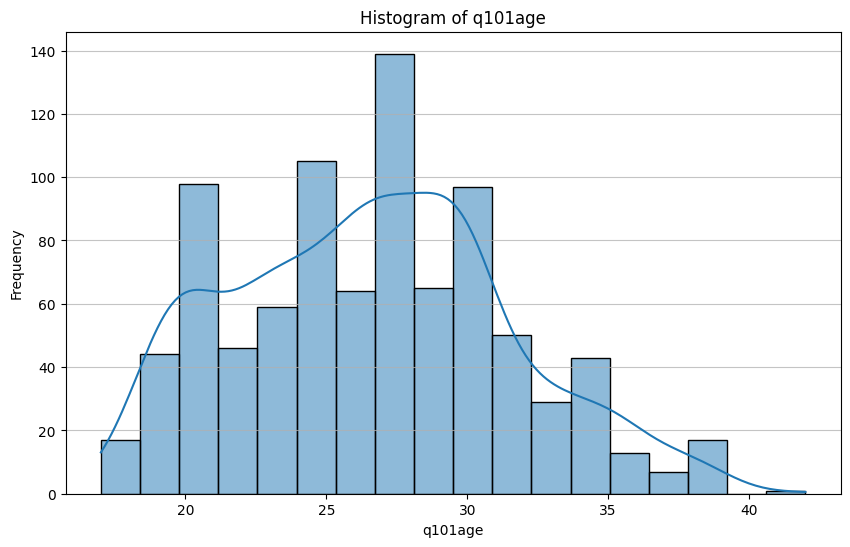

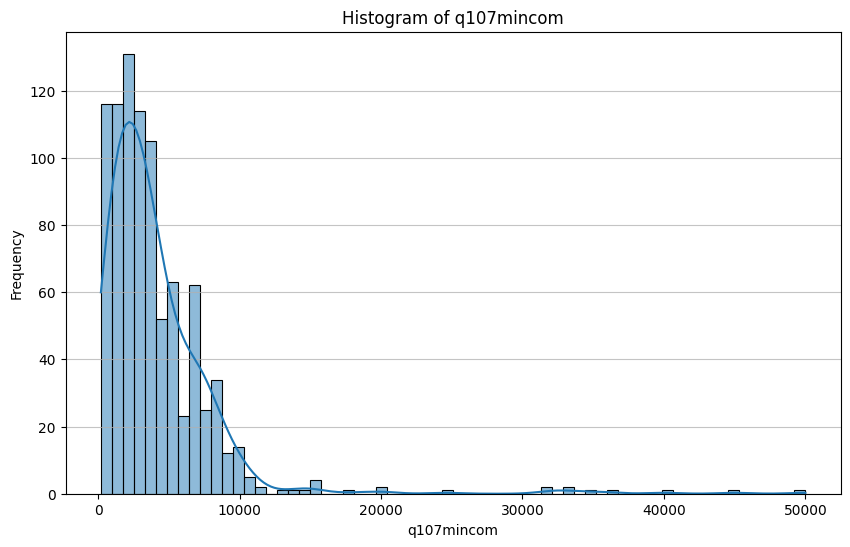

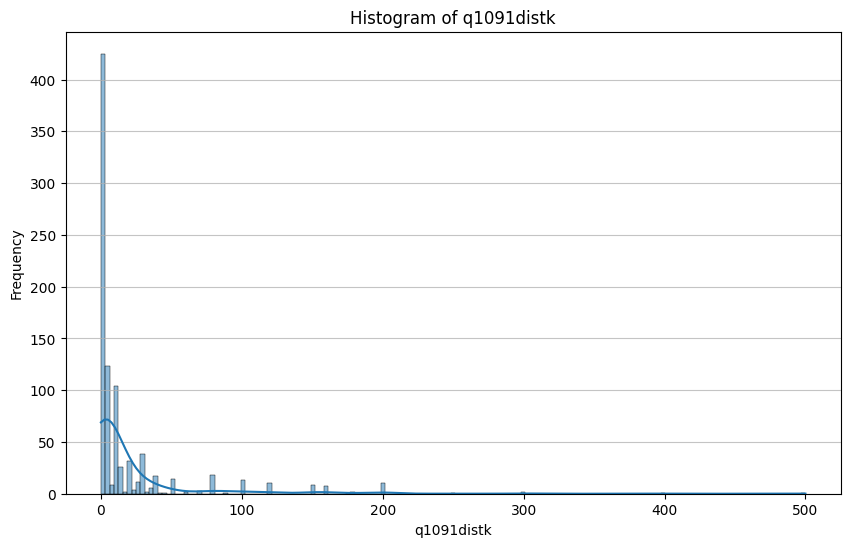

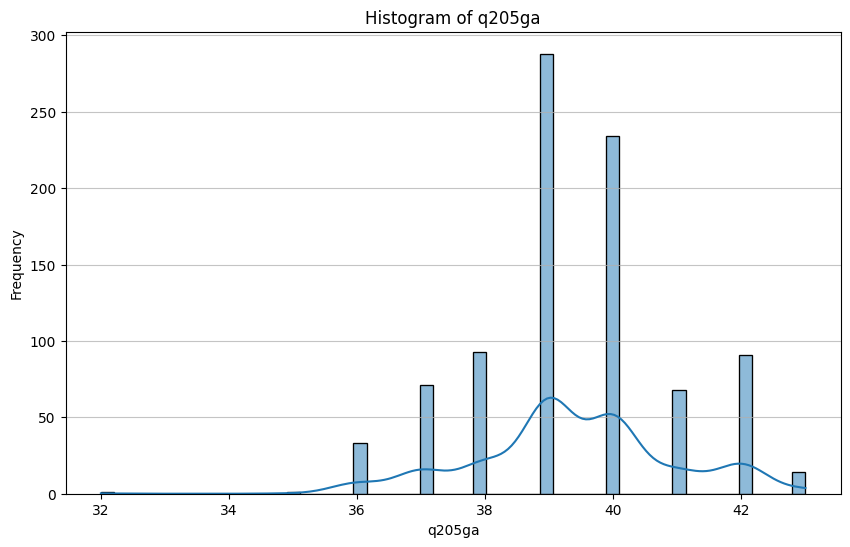

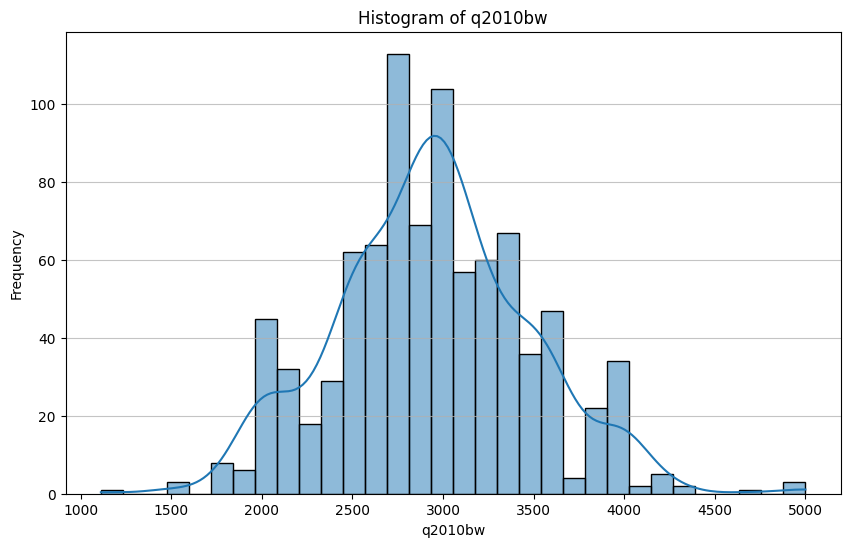

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in numerical_features:
    plt.figure(figsize=(10, 6))
    sns.histplot(df_clean[col], kde=True)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

**Explanation:** For each numerical feature, this draws a Seaborn histogram with a KDE (smoothed density) curve overlaid, plus a title, axis labels, and light gridlines. This gives a more detailed/prettier distribution view than the simple pandas histograms in an earlier cell.


*doing histogram for numerical variables*

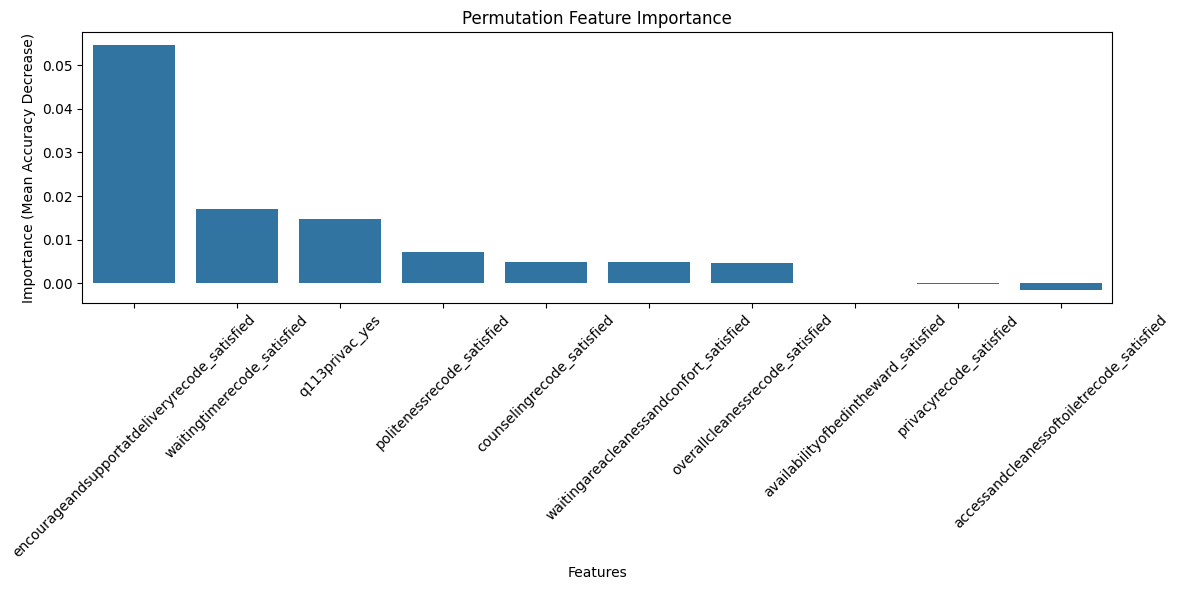

In [45]:
plt.figure(figsize=(12, 6))
sns.barplot(x=perm_importance.index, y=perm_importance.values)
plt.title('Permutation Feature Importance')
plt.xlabel('Features')
plt.ylabel('Importance (Mean Accuracy Decrease)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Explanation:** Plots a bar chart of permutation feature importance (features on the x-axis, importance score on the y-axis). Note: this cell uses the `perm_importance` variable, which is only calculated later in the notebook (in the permutation-importance cell near the end). For this cell to run without error, that later cell needs to be executed first — the notebook cells are not in strict top-to-bottom dependency order at this point.


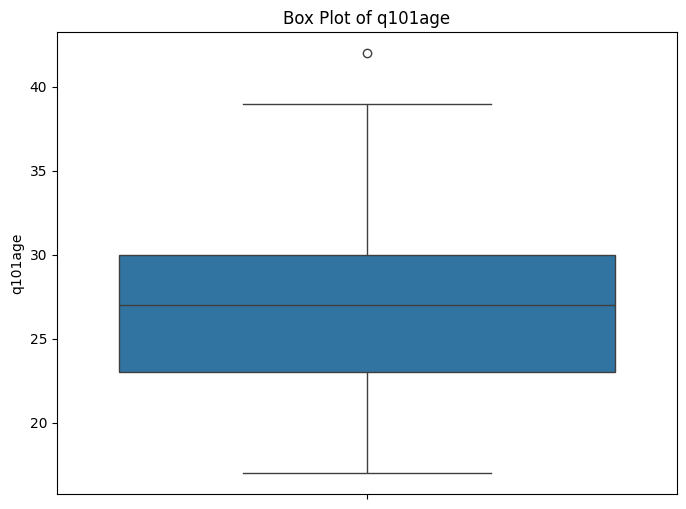

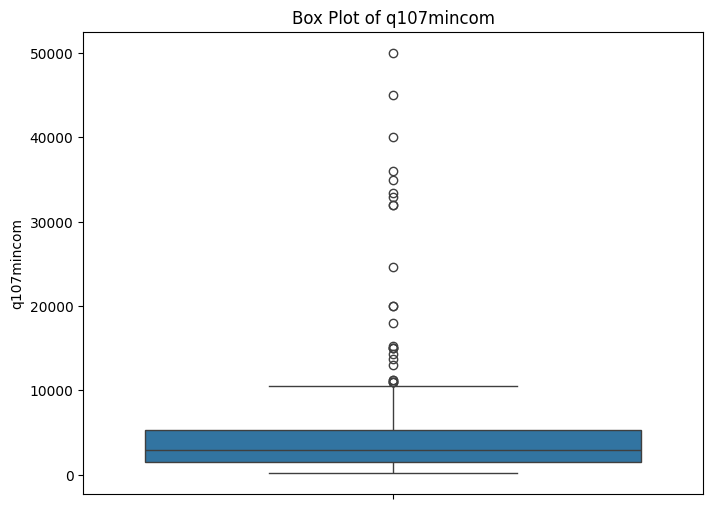

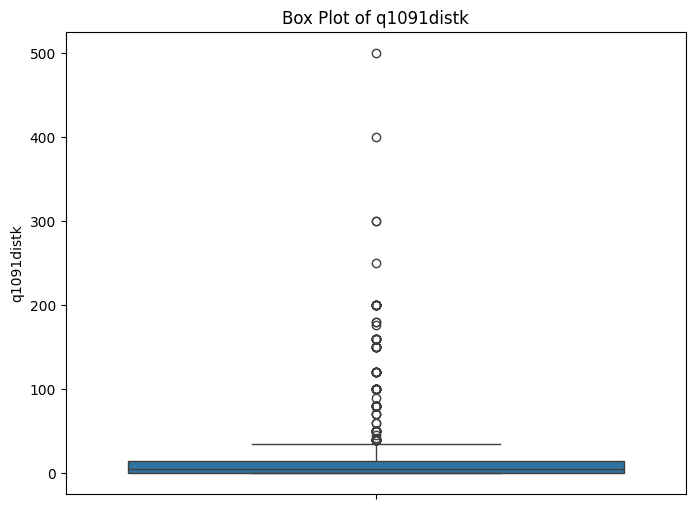

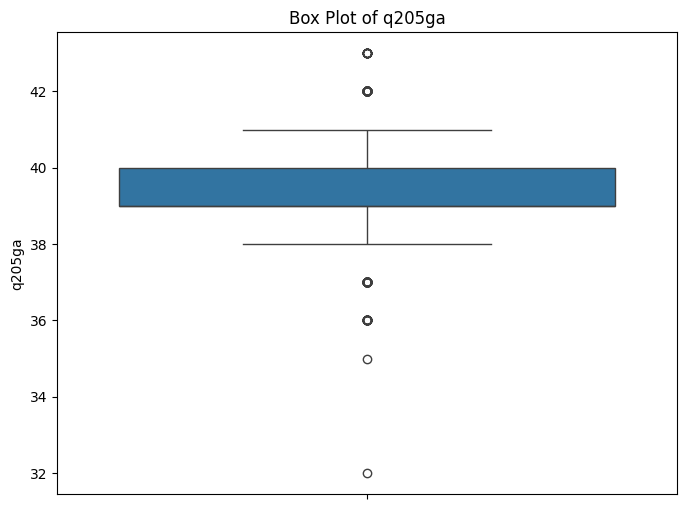

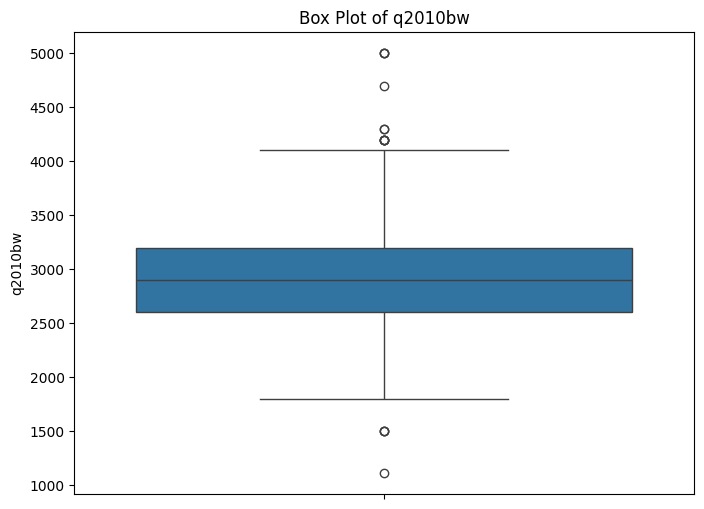

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in numerical_features:
    plt.figure(figsize=(8, 6))
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel(col)
    plt.show()

**Explanation:** For each numerical feature, this draws a Seaborn box plot. Box plots are useful for spotting outliers and seeing the spread (median, quartiles, min/max range) of each numeric variable.


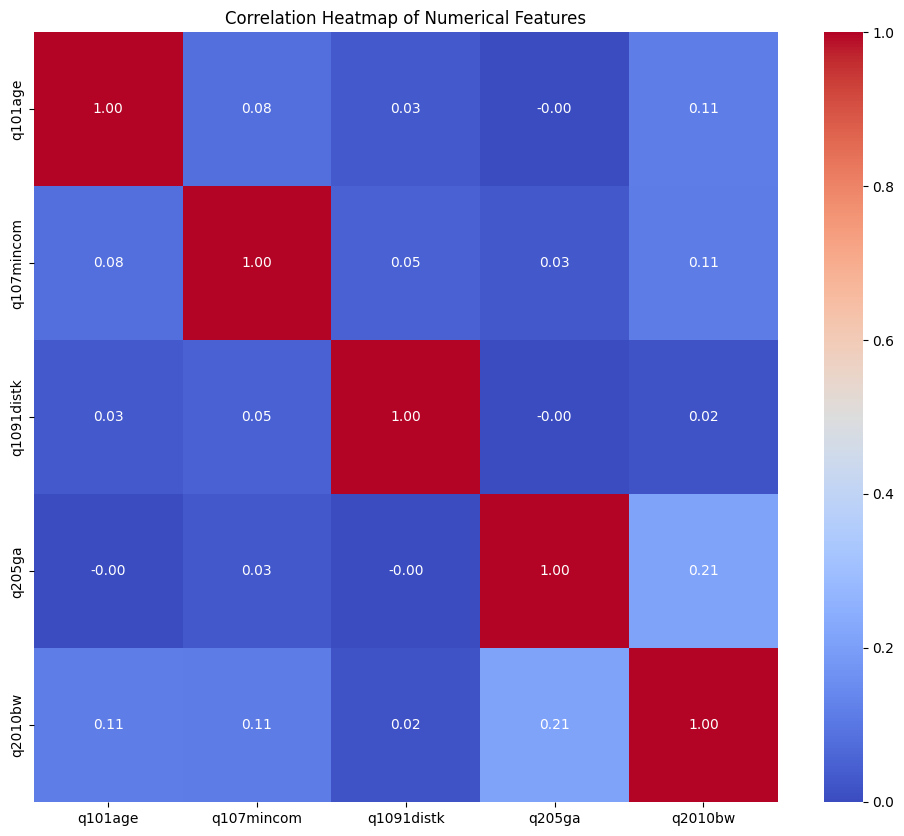

In [24]:
plt.figure(figsize=(12, 10))
sns.heatmap(df_clean[numerical_features].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

**Explanation:** Computes the pairwise correlation matrix for all numerical features and displays it as a colour-coded heatmap (with the correlation values annotated on each cell). This helps identify which numeric variables move together (positively or negatively correlated).


mapping the target variable in to numeric value

In [25]:
y_=y.map({'satisfied':1,'not satisfied':0})
y_


,satisfaction
0,0
1,1
2,1
3,1
4,1
...,...
889,0
890,0
891,0
892,0


**Explanation:** Converts the target variable from text labels to numbers using `.map()`: `'satisfied'` becomes `1` and `'not satisfied'` becomes `0`. The result is stored in `y_`. Machine learning models need numeric targets, not text.


Encoding categorical variables  in to numeric values

In [26]:
x_encoded=pd.get_dummies(x,categorical_features,drop_first=True)
x_encoded

,q101age,q107mincom,q1091distk,q205ga,q2010bw,q102mstatu_divorced,q102mstatu_married,q102mstatu_single,q102mstatu_widowed,q103religi_muslim,...,privacyrecode_satisfied,encourageandsupportatdeliveryrecode_satisfied,politenessrecode_satisfied,availabilityofmedicalequipmentsrecode_satisfied,counselingrecode_satisfied,overallcleanessrecode_satisfied,accessandcleanessoftoiletrecode_satisfied,waitingareacleanessandconfort_satisfied,availabilityofbedintheward_satisfied,distancerecode1_>10 kilo meters
0,22.0,800.0,0.0,41.0,1111.0,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,35.0,7000.0,0.0,41.0,3000.0,False,True,False,False,False,...,True,True,True,True,True,True,True,True,True,False
2,20.0,1500.0,5.0,42.0,3000.0,False,True,False,False,False,...,True,True,True,True,True,True,True,True,True,False
3,26.0,900.0,0.0,39.0,2600.0,False,True,False,False,False,...,True,True,True,True,True,True,True,True,True,False
4,22.0,1536.0,5.0,39.0,2800.0,False,True,False,False,True,...,True,True,True,True,True,True,True,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
889,29.0,2200.0,30.0,41.0,3600.0,False,False,False,False,True,...,False,False,False,True,False,False,False,False,False,True
890,31.0,4530.0,20.0,37.0,2900.0,False,True,False,False,False,...,False,False,False,True,False,False,False,False,False,True
891,21.0,2500.0,0.0,43.0,3000.0,False,True,False,False,False,...,False,False,False,True,False,False,False,False,False,False
892,18.0,3230.0,15.0,43.0,2001.0,False,False,True,False,True,...,False,False,False,False,False,False,False,False,False,True


**Explanation:** `pd.get_dummies()` one-hot encodes all categorical columns — turning each category into its own 0/1 column. `drop_first=True` drops one category per variable to avoid redundant (perfectly correlated) columns. The result, `x_encoded`, is a fully numeric version of the feature set that a model can use.


In [27]:
x_encoded.columns

Index(['q101age', 'q107mincom', 'q1091distk', 'q205ga', 'q2010bw',
       'q102mstatu_divorced', 'q102mstatu_married', 'q102mstatu_single',
       'q102mstatu_widowed', 'q103religi_muslim', 'q103religi_orthodox',
       'q103religi_protestant', 'q104ethini_amhara', 'q104ethini_oromo',
       'q104ethini_tigrie', 'q105educat_diploma and above',
       'q105educat_grade 1 to 4', 'q105educat_grade 11 to 12',
       'q105educat_grade 5 to 8', 'q105educat_grade 9 to 10',
       'q105educat_unable to read and write', 'q106occupa_governmental',
       'q106occupa_huose wife', 'q106occupa_merchants', 'q106occupa_others',
       'q106occupa_students', 'q108reside_urban', 'q110reason_refered',
       'q111timeta_>1hr', 'q112waitpl_yes', 'q113privac_yes',
       'q201parity_2-5 childrens', 'q201parity_>5 childrens', 'q202cpplan_yes',
       'q203ancatt_yes', 'q204hivres_HIV positive', 'q204hivres_not tested',
       'q206delimo_assisted delivery',
       'q206delimo_spontaneous vaginal delivery',

**Explanation:** Prints the column names of `x_encoded`, letting us see exactly which new one-hot-encoded columns were created.


In [28]:
x_encoded.shape

(894, 67)

**Explanation:** `x_encoded.shape` shows how many rows and columns exist after one-hot encoding — the column count grows because each category became its own column.


In [29]:
x_encoded.head().T

,0,1,2,3,4
q101age,22.0,35.0,20.0,26.0,22.0
q107mincom,800.0,7000.0,1500.0,900.0,1536.0
q1091distk,0.0,0.0,5.0,0.0,5.0
q205ga,41.0,41.0,42.0,39.0,39.0
q2010bw,1111.0,3000.0,3000.0,2600.0,2800.0
...,...,...,...,...,...
overallcleanessrecode_satisfied,False,True,True,True,True
accessandcleanessoftoiletrecode_satisfied,False,True,True,True,True
waitingareacleanessandconfort_satisfied,False,True,True,True,True
availabilityofbedintheward_satisfied,False,True,True,True,True


**Explanation:** `x_encoded.head().T` shows the first 5 rows transposed (variables as rows, respondents as columns), which is often easier to scan when there are many encoded columns.


In [30]:
x_train,x_test,y_train,y_test=train_test_split(x_encoded,y_,test_size=0.2,random_state=42)

**Explanation:** Splits the encoded features (`x_encoded`) and numeric target (`y_`) into training and testing sets using `train_test_split`. 80% of the data goes to training (`x_train`, `y_train`) and 20% to testing (`x_test`, `y_test`), with `random_state=42` fixed so the split is reproducible.


In [33]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

**Explanation:** Creates a `StandardScaler` and uses it to standardize the numeric features (mean = 0, standard deviation = 1). `.fit_transform()` learns the scaling parameters from the training data and applies them; `.transform()` applies the *same* learned scaling to the test data (never re-fit on test data, to avoid data leakage).


***Selecting the  more necessaty variables for doing the model***

In [34]:
k_values = list(range(2, 68, 2)) + [67]
scores = []

# Loop to find the best k value for feature selection
for k in k_values:
    selector_temp = SelectKBest(score_func=f_classif, k=k)
    x_train_selected_temp = selector_temp.fit_transform(x_train_scaled, y_train)
    x_test_selected_temp = selector_temp.transform(x_test_scaled)

    model_temp = LogisticRegression()
    model_temp.fit(x_train_selected_temp, y_train)

    y_pred_temp = model_temp.predict(x_test_selected_temp)
    accuracy = accuracy_score(y_test, y_pred_temp)
    scores.append(accuracy)

best_k_index = np.argmax(scores)
best_k = k_values[best_k_index]
print("Best k found:", best_k)
print("Highest accuracy score for this k:", scores[best_k_index])

Best k found: 10
Highest accuracy score for this k: 0.9776536312849162


**Explanation:** This loop searches for the best number of features (`k`) to keep. For every candidate `k` in `k_values`, it:
1. Selects the top `k` features with `SelectKBest(score_func=f_classif)`.
2. Trains a fresh `LogisticRegression` model on just those `k` features.
3. Measures accuracy on the test set and stores it in `scores`.

After trying all values of `k`, it finds the `k` that produced the highest accuracy (`best_k`) and prints it along with that best accuracy score.


***Fitting the logistic regression model for this selected  variables***

In [35]:
# Train the final model with the best_k features
final_selector = SelectKBest(score_func=f_classif, k=best_k)
x_train_selected_final = final_selector.fit_transform(x_train_scaled, y_train)
x_test_selected_final = final_selector.transform(x_test_scaled)

final_model = LogisticRegression()
final_model.fit(x_train_selected_final, y_train)

# Get the top features for the final model using the final_selector
# x_encoded.columns is used to map the feature scores back to original feature names.
feature_scores = pd.Series(final_selector.scores_, index=x_encoded.columns)
top_features = feature_scores.nlargest(best_k).index.tolist()

print("\nShape of x_train_selected_final:", x_train_selected_final.shape)
print("Shape of x_test_selected_final:", x_test_selected_final.shape)
print("Top features (best_k=", best_k, "):", top_features)


Shape of x_train_selected_final: (715, 10)
Shape of x_test_selected_final: (179, 10)
Top features (best_k= 10 ): ['availabilityofbedintheward_satisfied', 'waitingareacleanessandconfort_satisfied', 'accessandcleanessoftoiletrecode_satisfied', 'overallcleanessrecode_satisfied', 'privacyrecode_satisfied', 'counselingrecode_satisfied', 'politenessrecode_satisfied', 'waitingtimerecode_satisfied', 'q113privac_yes', 'encourageandsupportatdeliveryrecode_satisfied']


**Explanation:** Retrains the final model using the best number of features found above:
1. `final_selector` selects the `best_k` best features (via the F-statistic) from the scaled training data.
2. `final_model`, a `LogisticRegression`, is trained on those selected features.
3. `feature_scores` maps each original column name to its selection score, and `top_features` lists the names of the `best_k` highest-scoring columns.
4. Prints the shapes of the selected training/testing data and the list of `top_features` — the specific survey questions that ended up mattering most.


In [36]:
x_train_selected_final.shape

(715, 10)

**Explanation:** Prints the shape of `x_train_selected_final` to confirm how many rows and (best_k) columns remain after feature selection.


In [37]:
print("\n".join(top_features))

availabilityofbedintheward_satisfied
waitingareacleanessandconfort_satisfied
accessandcleanessoftoiletrecode_satisfied
overallcleanessrecode_satisfied
privacyrecode_satisfied
counselingrecode_satisfied
politenessrecode_satisfied
waitingtimerecode_satisfied
q113privac_yes
encourageandsupportatdeliveryrecode_satisfied


**Explanation:** Prints each of the `top_features` names, one per line, for easy reading.


Doing train test split

***model prediction***


In [38]:
y_pred = final_model.predict(x_test_selected_final)
y_prob = final_model.predict_proba(x_test_selected_final)[:,1]


**Explanation:** Uses the trained `final_model` to make predictions on the held-out test set:
- `y_pred` — the predicted class (0 = not satisfied, 1 = satisfied) for each test respondent.
- `y_prob` — the predicted *probability* of being satisfied (class 1), taken from `predict_proba`.


***Doing an evaluation matrices for this logistic regression model***

In [39]:
accuracy=accuracy_score(y_test,y_pred)
cm=confusion_matrix(y_test,y_pred)
f1sc=f1_score(y_test,y_pred)
recal=recall_score(y_test,y_pred)
brier=brier_score_loss(y_test,y_prob)
precision=precision_score(y_test,y_pred)
auc=roc_curve(y_test,y_prob)

**Explanation:** Calculates several evaluation metrics comparing the true test labels (`y_test`) to the model's predictions:
- `accuracy` — overall fraction of correct predictions.
- `cm` — the confusion matrix (counts of true/false positives/negatives).
- `f1sc` — the F1 score (harmonic mean of precision and recall).
- `recal` — recall (how many actual "satisfied" cases were correctly found).
- `brier` — the Brier score loss (how well-calibrated the predicted probabilities are; lower is better).
- `precision` — precision (of predicted "satisfied" cases, how many were correct).
- `auc` — here this simply stores the raw output of `roc_curve()` (three arrays: false-positive rates, true-positive rates, thresholds), not the actual AUC number itself. The real AUC score is computed separately later with `roc_auc_score()`.


Showing the Evaluation matrices value

In [40]:
print("    accuracy     :",accuracy)
print("--- Confusion Matrix ---")
print(f"True Negatives (TN): {cm[0, 0]}")
print(f"False Positives (FP): {cm[0, 1]}")
print(f"False Negatives (FN): {cm[1, 0]}")
print(f"True Positives (TP): {cm[1, 1]}")
print("------------------------")
print("    f1score       :",f1sc)
print("recall           :",recal)
print("brier score loss :",brier)
print("     precision   :",precision)
#print(auc)

    accuracy     : 0.9776536312849162
--- Confusion Matrix ---
True Negatives (TN): 62
False Positives (FP): 2
False Negatives (FN): 2
True Positives (TP): 113
------------------------
    f1score       : 0.9826086956521739
recall           : 0.9826086956521739
brier score loss : 0.023667051320616472
     precision   : 0.9826086956521739


**Explanation:** Prints all the evaluation metrics calculated in the previous cell in a readable, labeled format: overall accuracy, the four confusion-matrix counts (True Negatives, False Positives, False Negatives, True Positives), F1 score, recall, Brier score loss, and precision.


Ploting an roc curve for this model

/tmp/ipykernel_7913/1227433997.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


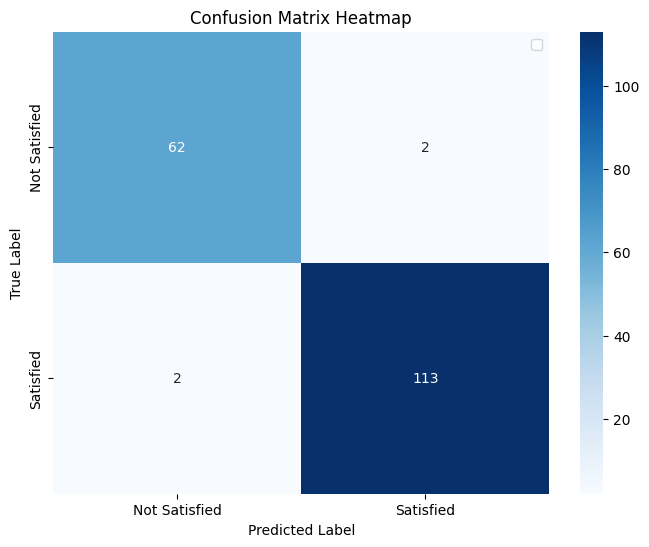

In [41]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Satisfied', 'Satisfied'],
            yticklabels=['Not Satisfied', 'Satisfied'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix Heatmap')
plt.legend()
plt.show()

**Explanation:** Draws the confusion matrix as a Seaborn heatmap with counts annotated in each cell, axis labels for predicted vs. true class, and the classes labeled "Not Satisfied"/"Satisfied" — a visual version of the confusion-matrix numbers printed above.


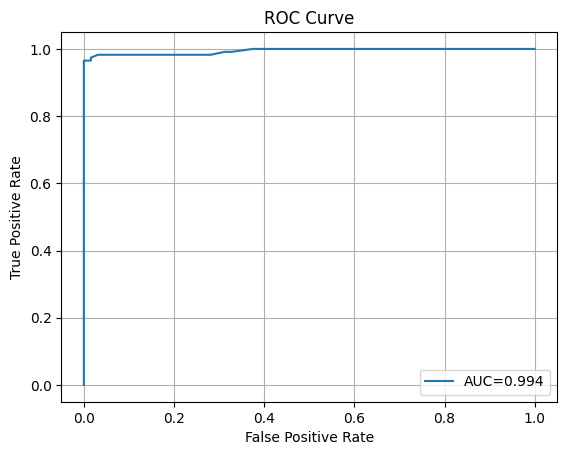

In [42]:
fpr,tpr,_=roc_curve(y_test,y_prob)
auc_score=roc_auc_score(y_test,y_prob) # Calculate the actual AUC score
plt.plot(fpr,tpr,label=f'AUC={auc_score:.3f}')
plt.title('ROC Curve')
plt.legend()
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.grid(True)
plt.show()

**Explanation:** Computes the ROC curve points (`fpr` = false-positive rate, `tpr` = true-positive rate) with `roc_curve`, calculates the overall Area Under the Curve with `roc_auc_score`, then plots the ROC curve with the AUC value shown in the legend. The ROC curve shows the trade-off between correctly detecting "satisfied" cases and incorrectly flagging "not satisfied" ones at different decision thresholds.


# Doing Feature importance

In [43]:
coef_importance = pd.Series(final_model.coef_[0], index=top_features).sort_values(key=abs, ascending=False)


**Explanation:** Builds a pandas Series of the logistic regression's learned coefficients (`final_model.coef_[0]`), labeled with the `top_features` names, and sorts them by absolute value (largest impact first, whether positive or negative). This shows which features push the prediction most strongly toward or away from "satisfied," according to the model's own weights.


# ***doing permutuation importance***

In [44]:
# Permutation Feature Importance is a model inspection technique that quantifies how much a model's performance decreases
# when a single feature's values are randomly shuffled. This helps to understand which features are most crucial for the model's predictions.
#
# In this code:
# - `permutation_importance` is used with the `final_model`, test data (`x_test_selected_final`, `y_test`).
# - `n_repeats=30` means the shuffling and evaluation are repeated 30 times to get a more robust average importance.
# - `scoring='accuracy'` indicates that the reduction in model accuracy is used to measure importance.
# - The results (`perm.importances_mean`) are then converted into a Pandas Series, indexed by the `top_features` (the features selected earlier), and sorted in descending order to easily see the most important ones.
#
# Interpretation of the output:
# - A higher positive value indicates that shuffling that feature significantly decreased the model's accuracy, meaning the feature is very important.
# - Values close to zero or slightly negative suggest that the feature is less important, or its shuffling has little to no impact, or could even slightly improve performance by chance (for slightly negative values).
perm = permutation_importance(final_model, x_test_selected_final, y_test, n_repeats=30, random_state=42, scoring='accuracy')
perm_importance = pd.Series(perm.importances_mean, index=top_features).sort_values(ascending=False)
print("Permutation Feature Importances:")
print(perm_importance)

Permutation Feature Importances:
encourageandsupportatdeliveryrecode_satisfied    0.054749
waitingtimerecode_satisfied                      0.016946
q113privac_yes                                   0.014711
politenessrecode_satisfied                       0.007076
counselingrecode_satisfied                       0.004842
waitingareacleanessandconfort_satisfied          0.004842
overallcleanessrecode_satisfied                  0.004655
availabilityofbedintheward_satisfied             0.000000
privacyrecode_satisfied                         -0.000186
accessandcleanessoftoiletrecode_satisfied       -0.001676
dtype: float64


**Explanation:** Calculates **permutation importance**: for each feature, its values in the test set are randomly shuffled (breaking its relationship with the outcome) and the model's accuracy is re-measured. Doing this `n_repeats=30` times per feature and averaging gives a robust importance score — the more accuracy drops when a feature is shuffled, the more important that feature actually is to the model's real predictions. Unlike the coefficient-based importance above, this method reflects the model's *actual* behavior rather than just its internal weights. The results are stored in `perm_importance`, sorted from most to least important, and printed.


In [46]:
import joblib
import os

# 1. Export the trained components necessary for preprocessing and prediction
joblib.dump(scaler, 'scaler.joblib')
joblib.dump(final_selector, 'selector.joblib')
joblib.dump(final_model, 'model.joblib')
joblib.dump(top_features, 'top_features.joblib')
joblib.dump(x_encoded.columns.tolist(), 'all_encoded_columns.joblib')

print("Model and preprocessing components successfully exported!")

# 2. Generate a clean Streamlit app script 'app.py' for interactive web deployment
streamlit_app_code = """
import streamlit as st
import pandas as pd
import numpy as np
import joblib

# Load the exported models and configurations
@st.cache_resource
def load_assets():
    scaler = joblib.load('scaler.joblib')
    selector = joblib.load('selector.joblib')
    model = joblib.load('model.joblib')
    top_features = joblib.load('top_features.joblib')
    all_columns = joblib.load('all_encoded_columns.joblib')
    return scaler, selector, model, top_features, all_columns

scaler, selector, model, top_features, all_columns = load_assets()

st.set_page_config(page_title="Delivery Care Satisfaction Predictor", layout="centered")
st.title("🤰 Delivery Care Satisfaction Predictor")
st.write('''
This application predicts maternal satisfaction with delivery care services based on the top clinical and facility features.
''')

st.subheader("Please provide the feedback on the following services:")

# Map friendly UI names to the exact feature column names
# The 10 critical binary features selected by your model:
feature_inputs = {}

# We will collect inputs for the top features
ui_mapping = {
    'availabilityofbedintheward_satisfied': ("Ward Bed Availability", ["satisfied", "not satisfied"]),
    'waitingareacleanessandconfort_satisfied': ("Waiting Area Cleanliness & Comfort", ["satisfied", "not satisfied"]),
    'accessandcleanessoftoiletrecode_satisfied': ("Toilet Cleanliness & Accessibility", ["satisfied", "not satisfied"]),
    'overallcleanessrecode_satisfied': ("Overall Facility Cleanliness", ["satisfied", "not satisfied"]),
    'privacyrecode_satisfied': ("Visual and Auditory Privacy", ["satisfied", "not satisfied"]),
    'counselingrecode_satisfied': ("Counseling Services Received", ["satisfied", "not satisfied"]),
    'politenessrecode_satisfied': ("Staff Politeness & Attitude", ["satisfied", "not satisfied"]),
    'waitingtimerecode_satisfied': ("Waiting Time", ["satisfied", "not satisfied"]),
    'q113privac_yes': ("Were you offered sufficient privacy? (Yes/No)", ["yes", "no"]),
    'encourageandsupportatdeliveryrecode_satisfied': ("Encouragement & Support During Delivery", ["satisfied", "not satisfied"])
}

for col in top_features:
    label, options = ui_mapping.get(col, (col, ["satisfied", "not satisfied"]))
    val = st.selectbox(label, options)
    # Map response to True/False representing the encoded dummy structure (e.g. '*_satisfied' == True)
    feature_inputs[col] = True if val in ["satisfied", "yes"] else False

if st.button("🔮 Predict Satisfaction"):
    # 1. Recreate the complete dummy row structure to fit the original Scaler
    input_row = pd.DataFrame(0, index=[0], columns=all_columns)

    # 2. Fill in the values for our user inputs
    for col, value in feature_inputs.items():
        input_row[col] = value

    # 3. Apply the pipeline transformations sequentially
    scaled_data = scaler.transform(input_row)
    selected_features = selector.transform(scaled_data)

    # 4. Run prediction
    prediction = model.predict(selected_features)[0]
    probability = model.predict_proba(selected_features)[0][1]

    st.markdown("--- ")
    if prediction == 1:
        st.success(f"🎉 **Predicted Outcome: Satisfied** (Probability: {probability:.2%})")
    else:
        st.warning(f"⚠️ **Predicted Outcome: Not Satisfied** (Probability of satisfaction: {probability:.2%})")
"""

with open('app.py', 'w') as f:
    f.write(streamlit_app_code.strip())

print("Streamlit 'app.py' file generated successfully! Run 'pip install streamlit' and 'streamlit run app.py' to launch it.")

Model and preprocessing components successfully exported!
Streamlit 'app.py' file generated successfully! Run 'pip install streamlit' and 'streamlit run app.py' to launch it.
